# Short-Term Electricity Demand Forecasting using PJME Data

## 1. Problem Framing
The aim is to forecast **daily electricity demand** for the PJME region using historical load data.

The raw data is hourly load in MW. After adding the 24 hourly observations for a day, the daily target is treated as total daily energy in **MWh**.

For this version, I compare simple baselines, a linear model and XGBoost. I also use time-based validation instead of random cross-validation because future observations should not be used to predict the past.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings('ignore')

## 2. Dataset Loading and Daily Aggregation
The file `PJME_hourly.csv` contains hourly load observations. I sort the data by time and aggregate it to daily values.

A few dates do not contain exactly 24 hourly observations. I remove those dates so that an incomplete day is not compared with a complete 24-hour day.

In [2]:
print("Loading PJME_hourly.csv...")

df = pd.read_csv('PJME_hourly.csv', parse_dates=['Datetime'])
df = df.set_index('Datetime').sort_index()

# Number of hourly readings available on each date
hourly_counts = df.resample('D').count()['PJME_MW']
complete_days = hourly_counts[hourly_counts == 24].index

# Sum hourly MW observations to get the daily energy total (MWh)
df_daily = df.resample('D').sum()
df_daily.rename(columns={'PJME_MW': 'Demand_MWh'}, inplace=True)
df_daily = df_daily.loc[df_daily.index.isin(complete_days)]
df_daily = df_daily[df_daily['Demand_MWh'] > 0]

print(f"Daily observations: {len(df_daily)}")
print(f"Date range: {df_daily.index.min().date()} to {df_daily.index.max().date()}")
display(df_daily.head())

Loading PJME_hourly.csv...
Daily observations: 6023
Date range: 2002-01-02 to 2018-08-02


,Demand_MWh
Datetime,
2002-01-02,822277.0
2002-01-03,828285.0
2002-01-04,809171.0
2002-01-05,729723.0
2002-01-06,727766.0


## 3. Exploratory Data Analysis
I first plot the complete daily series to see the long-term pattern and repeated seasonal changes.

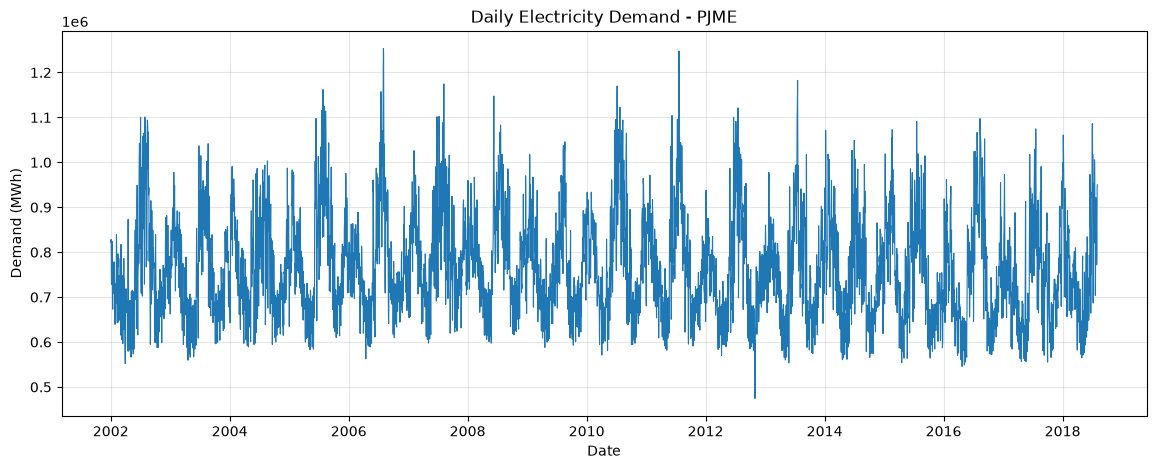

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(df_daily.index, df_daily['Demand_MWh'], linewidth=0.8)
plt.title('Daily Electricity Demand - PJME')
plt.xlabel('Date')
plt.ylabel('Demand (MWh)')
plt.grid(alpha=0.3)
plt.show()

## 4. ADF Test and Autocorrelation
I use the ADF test mainly to understand the time-series properties of the demand data. XGBoost itself does not require the target series to be stationary.

For the ADF test:
- Null hypothesis: the series has a unit root (non-stationary).
- A small p-value gives evidence against the null hypothesis.

The ACF plot is also useful for seeing how strongly current demand is related to previous days.

ADF Statistic: -8.481
p-value: 1.3910e-13
The ADF test rejects the unit-root null hypothesis at the 5% level.


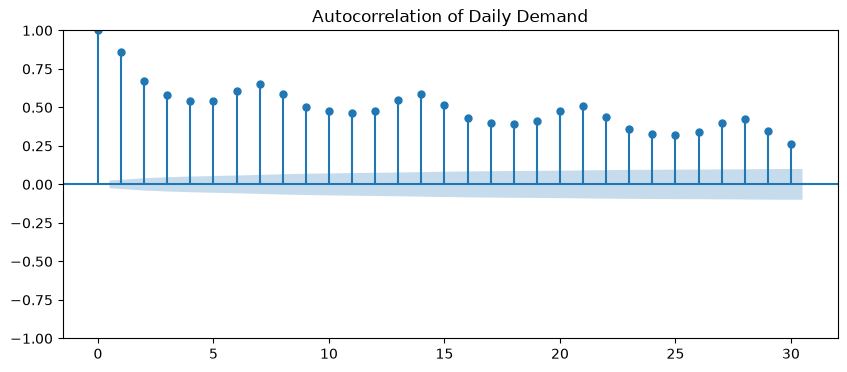

In [4]:
adf_result = adfuller(df_daily['Demand_MWh'])
print(f"ADF Statistic: {adf_result[0]:.3f}")
print(f"p-value: {adf_result[1]:.4e}")

if adf_result[1] < 0.05:
    print("The ADF test rejects the unit-root null hypothesis at the 5% level.")
else:
    print("The ADF test does not reject the unit-root null hypothesis at the 5% level.")

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(df_daily['Demand_MWh'], lags=30, ax=ax)
ax.set_title('Autocorrelation of Daily Demand')
plt.show()

## 5. Feature Engineering
The model needs numerical features that summarize recent demand and calendar effects.

I use:
- calendar variables: day of week, month and weekend indicator,
- annual cyclic variables using sine and cosine of day-of-year,
- demand lags from 1 to 28 days,
- rolling means and rolling standard deviations over 7, 14 and 28 days.

All lag and rolling features are based only on values available before the prediction date.

In [5]:
df_ml = df_daily.copy()

# Calendar features
df_ml['day_of_week'] = df_ml.index.dayofweek
df_ml['month'] = df_ml.index.month
df_ml['is_weekend'] = (df_ml['day_of_week'] >= 5).astype(int)

day_of_year = df_ml.index.dayofyear
df_ml['sin_doy'] = np.sin(2 * np.pi * day_of_year / 365.25)
df_ml['cos_doy'] = np.cos(2 * np.pi * day_of_year / 365.25)

# Lag features
for lag in [1, 2, 3, 7, 14, 28]:
    df_ml[f'lag_{lag}'] = df_ml['Demand_MWh'].shift(lag)

# Rolling features. shift(1) makes sure today's value is not included.
past_demand = df_ml['Demand_MWh'].shift(1)
for window in [7, 14, 28]:
    df_ml[f'rolling_mean_{window}'] = past_demand.rolling(window).mean()
    df_ml[f'rolling_std_{window}'] = past_demand.rolling(window).std()

df_ml.dropna(inplace=True)

feature_cols = [c for c in df_ml.columns if c != 'Demand_MWh']

print(f"Number of features: {len(feature_cols)}")
print(feature_cols)
display(df_ml.head())

Number of features: 17
['day_of_week', 'month', 'is_weekend', 'sin_doy', 'cos_doy', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_mean_28', 'rolling_std_28']


,Demand_MWh,day_of_week,month,is_weekend,sin_doy,cos_doy,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,rolling_mean_7,rolling_std_7,rolling_mean_14,rolling_std_14,rolling_mean_28,rolling_std_28
Datetime,,,,,,,,,,,,,,,,,,
2002-01-30,685796.0,2,1,0,0.493468,0.869764,696677.0,707708.0,639494.0,755864.0,768234.0,822277.0,704681.857143,39133.490024,731743.142857,41825.483625,748548.178571,49204.574434
2002-01-31,729020.0,3,1,0,0.508356,0.861147,685796.0,696677.0,707708.0,734778.0,765151.0,828285.0,694672.142857,32208.392904,725854.714286,42095.085638,743673.857143,48383.528902
2002-02-01,711909.0,4,2,0,0.523094,0.852275,729020.0,685796.0,696677.0,724412.0,769035.0,809171.0,693849.571429,31066.709373,723273.928571,40580.902715,740128.678571,45505.333976
2002-02-02,687530.0,5,2,1,0.537677,0.843151,711909.0,729020.0,685796.0,673840.0,766232.0,729723.0,692063.428571,29327.436994,719193.500000,38441.276921,736655.035714,43716.896896
2002-02-03,686370.0,6,2,1,0.552101,0.833777,687530.0,711909.0,729020.0,639494.0,707590.0,727766.0,694019.142857,28349.827339,713571.928571,36750.762277,735148.142857,44681.235887


## 6. Final Train/Test Split
I keep 2018 as the final test period. It is not used during the walk-forward comparison or parameter selection below.

The training data contains observations before 1 January 2018, while the test data contains the part of 2018 available in the dataset.

In [6]:
split_date = '2018-01-01'

train = df_ml[df_ml.index < split_date]
test = df_ml[df_ml.index >= split_date]

X_train = train[feature_cols]
y_train = train['Demand_MWh']
X_test = test[feature_cols]
y_test = test['Demand_MWh']

print(f"Training days: {len(train)}")
print(f"Final test days: {len(test)}")
print(f"Test period: {test.index.min().date()} to {test.index.max().date()}")

Training days: 5782
Final test days: 213
Test period: 2018-01-01 to 2018-08-02


## 7. Baseline Models
Before using XGBoost, I compare it with simple forecasts.

1. **Yesterday baseline:** today's demand is predicted using yesterday's demand.
2. **Weekly baseline:** today's demand is predicted using demand from 7 days ago.
3. **Linear Regression:** uses the same engineered features as XGBoost.

The simple baselines are useful because an ML model should give a meaningful improvement over rules that are almost free to use.

In [7]:
# Final-test baseline predictions
yesterday_preds = test['lag_1']
weekly_preds = test['lag_7']

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_preds = pd.Series(linear_model.predict(X_test), index=test.index)

# Initial XGBoost settings before tuning
initial_xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    n_jobs=2
)
initial_xgb.fit(X_train, y_train)
initial_xgb_preds = pd.Series(initial_xgb.predict(X_test), index=test.index)

## 8. Walk-Forward Validation
A single train/test split may depend too much on one particular year. I therefore check the models on 2015, 2016 and 2017 separately.

For each validation year, the model is trained only on earlier observations. The training window expands as time moves forward.

In [8]:
validation_years = [2015, 2016, 2017]
walk_forward_rows = []

for year in validation_years:
    fold_train = df_ml[df_ml.index < f'{year}-01-01']
    fold_valid = df_ml[(df_ml.index >= f'{year}-01-01') &
                       (df_ml.index < f'{year + 1}-01-01')]

    X_fold_train = fold_train[feature_cols]
    y_fold_train = fold_train['Demand_MWh']
    X_fold_valid = fold_valid[feature_cols]
    y_fold_valid = fold_valid['Demand_MWh']

    # Baselines
    yesterday_mape = mean_absolute_percentage_error(y_fold_valid, fold_valid['lag_1']) * 100
    weekly_mape = mean_absolute_percentage_error(y_fold_valid, fold_valid['lag_7']) * 100

    # Linear regression
    lr = LinearRegression()
    lr.fit(X_fold_train, y_fold_train)
    lr_pred = lr.predict(X_fold_valid)
    lr_mape = mean_absolute_percentage_error(y_fold_valid, lr_pred) * 100

    # Initial XGBoost
    xgb = XGBRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=5,
        random_state=42, n_jobs=2
    )
    xgb.fit(X_fold_train, y_fold_train)
    xgb_pred = xgb.predict(X_fold_valid)
    xgb_mape = mean_absolute_percentage_error(y_fold_valid, xgb_pred) * 100

    walk_forward_rows.append({
        'Validation Year': year,
        'Yesterday MAPE (%)': yesterday_mape,
        'Weekly MAPE (%)': weekly_mape,
        'Linear Regression MAPE (%)': lr_mape,
        'XGBoost MAPE (%)': xgb_mape
    })

walk_forward_results = pd.DataFrame(walk_forward_rows).set_index('Validation Year')
display(walk_forward_results.round(2))

print("Average MAPE across the three validation years:")
display(walk_forward_results.mean().to_frame('Average MAPE (%)').round(2))

,Yesterday MAPE (%),Weekly MAPE (%),Linear Regression MAPE (%),XGBoost MAPE (%)
Validation Year,,,,
2015,5.72,9.68,4.60,4.39
2016,5.53,9.53,4.50,4.28
2017,6.07,10.31,5.11,4.74


Average MAPE across the three validation years:


,Average MAPE (%)
Yesterday MAPE (%),5.77
Weekly MAPE (%),9.84
Linear Regression MAPE (%),4.74
XGBoost MAPE (%),4.47


## 9. Small Hyperparameter Search
Instead of using a large automated search, I try a small set of XGBoost settings and choose the combination with the lowest average MAPE across the same walk-forward years.

I vary only three parameters:
- number of trees,
- tree depth,
- learning rate.

This keeps the tuning process small enough to inspect manually.

In [9]:
param_grid = []
for n_estimators in [200, 400]:
    for max_depth in [3, 5]:
        for learning_rate in [0.03, 0.05]:
            param_grid.append({
                'n_estimators': n_estimators,
                'max_depth': max_depth,
                'learning_rate': learning_rate
            })

tuning_rows = []

for params in param_grid:
    fold_mapes = []

    for year in validation_years:
        fold_train = df_ml[df_ml.index < f'{year}-01-01']
        fold_valid = df_ml[(df_ml.index >= f'{year}-01-01') &
                           (df_ml.index < f'{year + 1}-01-01')]

        model = XGBRegressor(
            **params,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=42,
            n_jobs=2
        )

        model.fit(fold_train[feature_cols], fold_train['Demand_MWh'])
        pred = model.predict(fold_valid[feature_cols])
        fold_mape = mean_absolute_percentage_error(fold_valid['Demand_MWh'], pred) * 100
        fold_mapes.append(fold_mape)

    tuning_rows.append({
        **params,
        'mean_validation_mape': np.mean(fold_mapes)
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values('mean_validation_mape')
display(tuning_results.round(3))

best_row = tuning_results.iloc[0]
best_params = {
    'n_estimators': int(best_row['n_estimators']),
    'max_depth': int(best_row['max_depth']),
    'learning_rate': float(best_row['learning_rate'])
}

print("Selected parameters:", best_params)

,n_estimators,max_depth,learning_rate,mean_validation_mape
6,400,5,0.03,4.381
5,400,3,0.05,4.385
7,400,5,0.05,4.448
3,200,5,0.05,4.454
2,200,5,0.03,4.460
4,400,3,0.03,4.469
1,200,3,0.05,4.509
0,200,3,0.03,4.691


Selected parameters: {'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.03}


## 10. Final Model Evaluation
I now fit the selected XGBoost model on all pre-2018 data and evaluate it once on the untouched 2018 test period.

I report MAE, RMSE and MAPE so that both absolute and percentage errors can be seen.

In [10]:
xgb_model = XGBRegressor(
    **best_params,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=2
)

xgb_model.fit(X_train, y_train)
xgb_preds = pd.Series(xgb_model.predict(X_test), index=test.index)

def get_metrics(y_true, y_pred):
    return {
        'MAE (MWh)': mean_absolute_error(y_true, y_pred),
        'RMSE (MWh)': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': mean_absolute_percentage_error(y_true, y_pred) * 100
    }

results = pd.DataFrame({
    'Yesterday Baseline': get_metrics(y_test, yesterday_preds),
    'Weekly Baseline': get_metrics(y_test, weekly_preds),
    'Linear Regression': get_metrics(y_test, linear_preds),
    'XGBoost (Initial)': get_metrics(y_test, initial_xgb_preds),
    'XGBoost (Tuned)': get_metrics(y_test, xgb_preds)
}).T

display(results.round(2))

,MAE (MWh),RMSE (MWh),MAPE (%)
Yesterday Baseline,48834.63,64289.45,6.45
Weekly Baseline,79030.51,106862.22,10.11
Linear Regression,39433.28,52143.79,5.14
XGBoost (Initial),38761.49,50965.29,5.05
XGBoost (Tuned),38775.79,51273.06,5.05


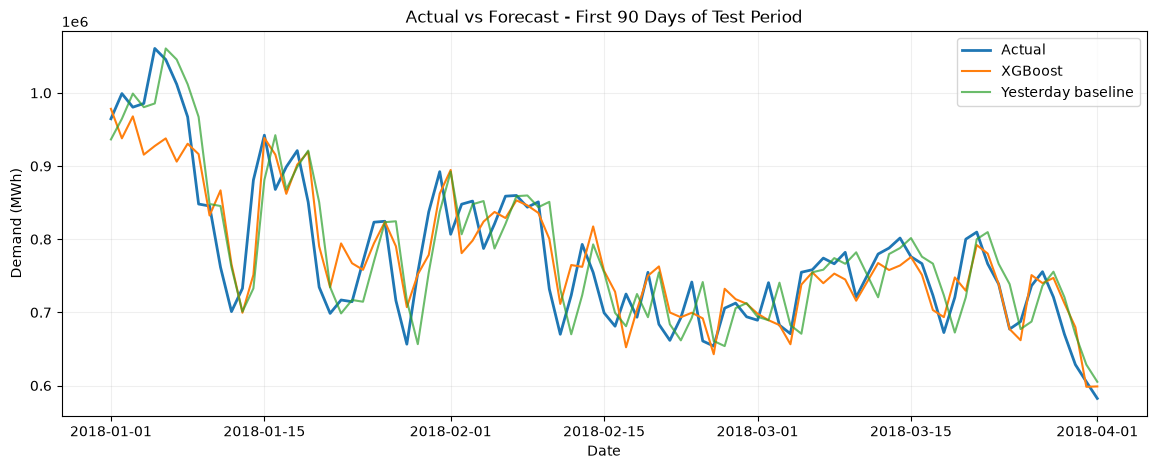

In [11]:
plt.figure(figsize=(14, 5))
plt.plot(y_test.index[:90], y_test.values[:90], label='Actual', linewidth=2)
plt.plot(y_test.index[:90], xgb_preds.values[:90], label='XGBoost', linewidth=1.5)
plt.plot(y_test.index[:90], yesterday_preds.values[:90], label='Yesterday baseline', alpha=0.7)
plt.title('Actual vs Forecast - First 90 Days of Test Period')
plt.xlabel('Date')
plt.ylabel('Demand (MWh)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 11. Feature Importance
XGBoost also gives a simple importance score for each input feature. This is not a causal interpretation, but it helps show which variables the fitted model relied on most.

,Importance
lag_1,0.4795
is_weekend,0.1976
rolling_mean_7,0.1004
day_of_week,0.0747
rolling_mean_14,0.0247
lag_2,0.0167
cos_doy,0.0162
rolling_mean_28,0.0119
sin_doy,0.0111
lag_7,0.0107


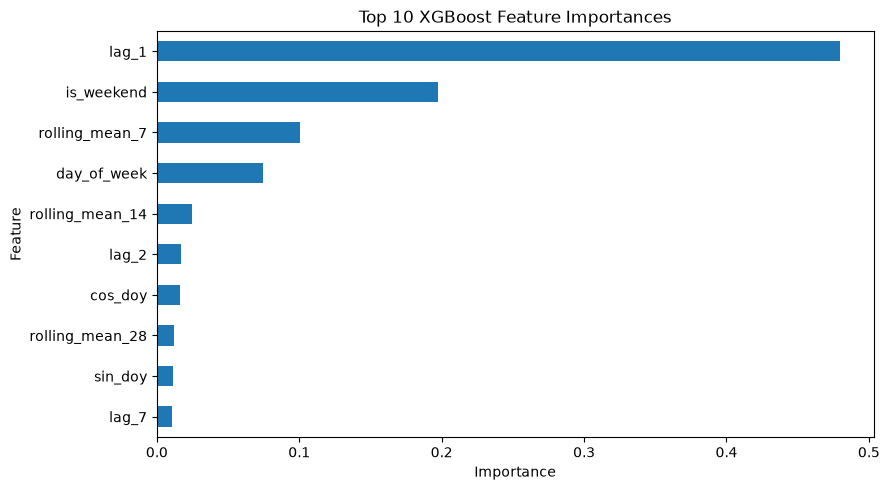

In [12]:
feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

importance_table = feature_importance.to_frame('Importance')
display(importance_table.head(10).round(4))

plt.figure(figsize=(9, 5))
feature_importance.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 XGBoost Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 12. Residual Check
Finally, I look at the one-day-ahead XGBoost errors. The Ljung-Box test checks whether there is still autocorrelation left in the residuals.

A significant result suggests that some time-related structure is still not being captured by the model. It does not mean that every missing pattern can necessarily be recovered from the current features.

Ljung-Box test at lag 7:


,lb_stat,lb_pvalue
7,12.688464,0.080073


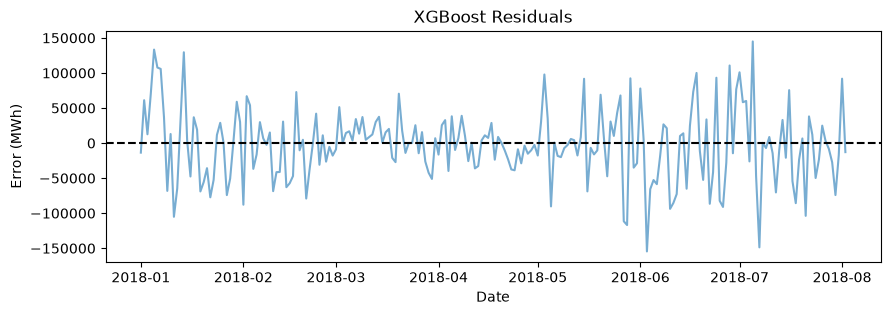

In [13]:
residuals = y_test - xgb_preds

lb_test = acorr_ljungbox(residuals, lags=[7], return_df=True)
print("Ljung-Box test at lag 7:")
display(lb_test)

plt.figure(figsize=(10, 3))
plt.plot(residuals.index, residuals.values, alpha=0.6)
plt.axhline(0, linestyle='--', color='black')
plt.title('XGBoost Residuals')
plt.xlabel('Date')
plt.ylabel('Error (MWh)')
plt.show()

## 13. Conclusion

Main observations from this version:
- The simple **yesterday** baseline is much stronger than the weekly baseline, so it is a more useful benchmark.
- Linear Regression is already competitive once lag and rolling features are included.
- XGBoost performs better across the walk-forward validation years and improves further after a small parameter search.
- `lag_1` and recent rolling demand are among the most important inputs, which is reasonable because electricity demand is strongly related to recent demand.
- The final test is kept separate from tuning, so the reported 2018 performance is a cleaner estimate of out-of-sample performance.

A clear limitation is that the model uses only historical demand and calendar information. Weather variables such as temperature would be a natural next extension.